In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv(
    r"C:\Users\pooja\Downloads\cynaris\cynaris-internship-pooja\week2_day4\cleaned_dataset.csv"
)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (120, 8)


,sale_id,sale_date,region,category,product,quantity,sales_amount,profit
0,1,2026-01-05,karnataka,electronics,laptop,2.0,77500.0,10000.0
1,2,2026-01-10,kerala,furniture,chair,5.0,15000.0,3000.0
2,3,2026-02-12,tamil nadu,electronics,mobile,3.0,45000.0,7000.0
3,4,2026-02-15,karnataka,clothing,shirt,9.5,10000.0,2500.0
4,5,2026-03-05,kerala,electronics,tablet,4.0,40000.0,6000.0


In [2]:
# Define events A and B
A = df["sales_amount"] > df["sales_amount"].mean()
B = df["profit"] > df["profit"].mean()

# Total number of sales
total = len(df)

# Calculate probabilities
P_A = A.sum() / total
P_B = B.sum() / total
P_A_and_B = (A & B).sum() / total
P_A_given_B = (A & B).sum() / B.sum()

print("P(A):", round(P_A, 3))
print("P(B):", round(P_B, 3))
print("P(A and B):", round(P_A_and_B, 3))
print("P(A given B):", round(P_A_given_B, 3))

P(A): 0.4
P(B): 0.4
P(A and B): 0.4
P(A given B): 1.0


In [3]:
# Create a contingency table
contingency_table = pd.crosstab(
    A,
    B,
    rownames=["Above Average Sales"],
    colnames=["Above Average Profit"]
)

contingency_table

Above Average Profit,False,True
Above Average Sales,,
False,72,0
True,0,48


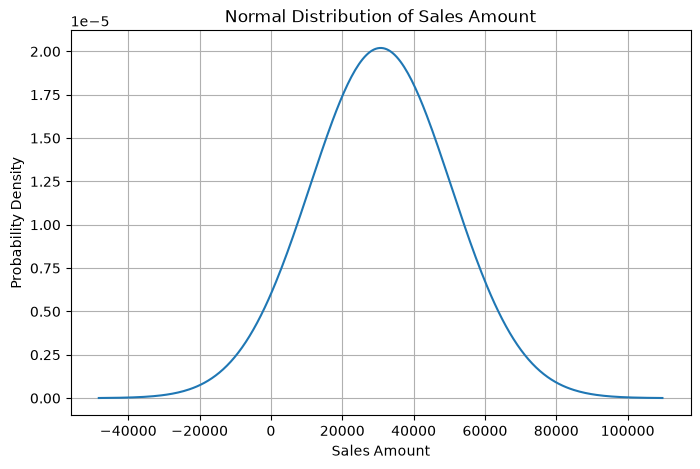

In [4]:
# Calculate mean and standard deviation
mean_value = df["sales_amount"].mean()
std_value = df["sales_amount"].std()

# Generate values for the curve
x = np.linspace(
    mean_value - 4 * std_value,
    mean_value + 4 * std_value,
    300
)

# Normal distribution formula
y = (1 / (std_value * np.sqrt(2 * np.pi))) * np.exp(
    -0.5 * ((x - mean_value) / std_value) ** 2
)

# Plot the distribution
plt.figure(figsize=(8, 5))
plt.plot(x, y)
plt.title("Normal Distribution of Sales Amount")
plt.xlabel("Sales Amount")
plt.ylabel("Probability Density")
plt.grid()
plt.show()

In [5]:
mean_value = df["sales_amount"].mean()
std_value = df["sales_amount"].std()

within_1 = df[
    (df["sales_amount"] >= mean_value - std_value) &
    (df["sales_amount"] <= mean_value + std_value)
]

within_2 = df[
    (df["sales_amount"] >= mean_value - 2 * std_value) &
    (df["sales_amount"] <= mean_value + 2 * std_value)
]

within_3 = df[
    (df["sales_amount"] >= mean_value - 3 * std_value) &
    (df["sales_amount"] <= mean_value + 3 * std_value)
]

print("Within 1 SD:", round(len(within_1) / len(df) * 100, 2), "%")
print("Within 2 SD:", round(len(within_2) / len(df) * 100, 2), "%")
print("Within 3 SD:", round(len(within_3) / len(df) * 100, 2), "%")

Within 1 SD: 80.0 %
Within 2 SD: 90.0 %
Within 3 SD: 100.0 %


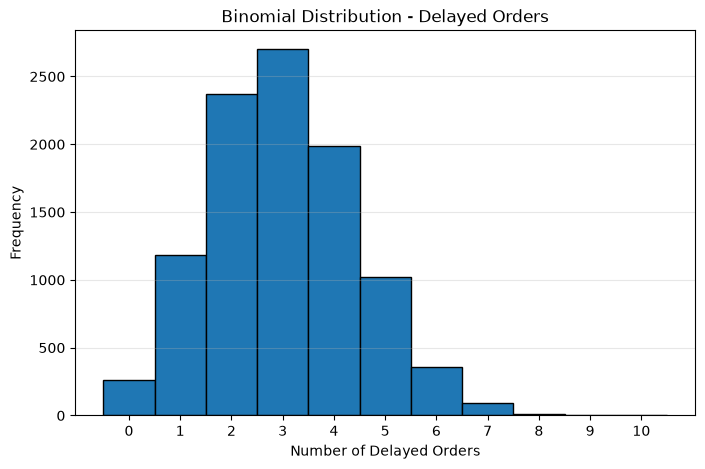

Average delayed orders: 3.0011


In [6]:
# Number of orders
n = 10

# Probability of one order being delayed
p = 0.30

# Run 10,000 simulations
simulations = np.random.binomial(n, p, 10000)

# Plot the results
plt.figure(figsize=(8, 5))
plt.hist(
    simulations,
    bins=np.arange(-0.5, n + 1.5, 1),
    edgecolor="black"
)

plt.title("Binomial Distribution - Delayed Orders")
plt.xlabel("Number of Delayed Orders")
plt.ylabel("Frequency")
plt.xticks(range(n + 1))
plt.grid(axis="y", alpha=0.3)
plt.show()

print("Average delayed orders:", simulations.mean())

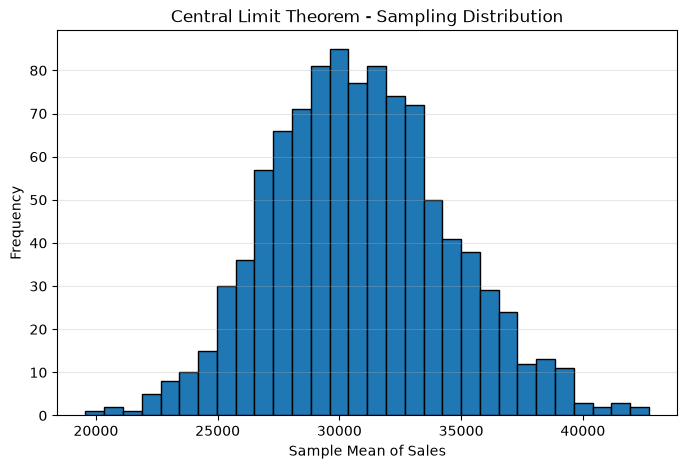

Original Sales Mean: 30750.0
Mean of Sample Means: 30857.31666666667


In [7]:
# Store sample averages
sample_means = []

# Take 1000 samples, each containing 30 sales
for i in range(1000):
    sample = df["sales_amount"].sample(
        n=30,
        replace=True
    )
    sample_means.append(sample.mean())

# Plot the sample averages
plt.figure(figsize=(8, 5))
plt.hist(sample_means, bins=30, edgecolor="black")

plt.title("Central Limit Theorem - Sampling Distribution")
plt.xlabel("Sample Mean of Sales")
plt.ylabel("Frequency")
plt.grid(axis="y", alpha=0.3)
plt.show()

print("Original Sales Mean:", df["sales_amount"].mean())
print("Mean of Sample Means:", np.mean(sample_means))


## Week 4 Day 2 – Probability Analysis

### 1. Probability
Probability measures the likelihood of an event happening. Its value ranges from 0 to 1.

### 2. Conditional Probability
Conditional probability measures the probability of an event happening when another event has already occurred.

### 3. Contingency Table
A contingency table helps identify relationships between two categorical events.

### 4. Normal Distribution
A normal distribution is a bell-shaped curve where most values are concentrated around the mean.

### 5. 68-95-99.7 Rule
- 68% of values fall within 1 standard deviation.
- 95% fall within 2 standard deviations.
- 99.7% fall within 3 standard deviations.

### 6. Binomial Distribution
Binomial distribution calculates the number of successes in a fixed number of independent attempts.

### 7. Central Limit Theorem
CLT explains that the distribution of sample means tends to become normal when we take many sufficiently large random samples.

### Conclusion
I used Python, Pandas, NumPy and Matplotlib to calculate probabilities, create distribution plots and perform simulations. These concepts help businesses analyse sales, delivery delays and customer behaviour.
